In [2]:
# !pip install torch numpy matplotlib

In [3]:
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
%matplotlib inline

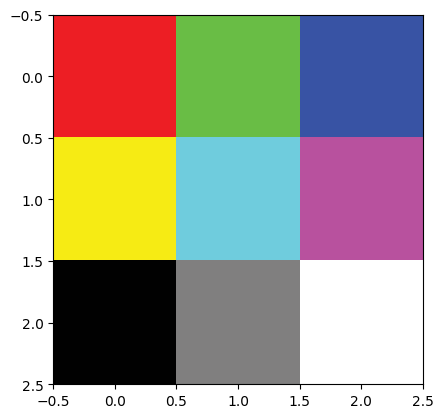

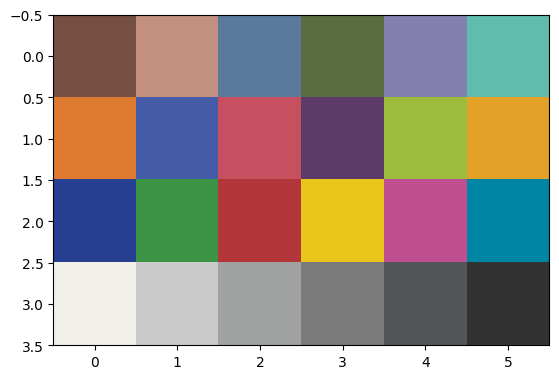

In [21]:
# 推論データ
X =  np.array([[0.3969, 0.0481, 0.0422],
[0.2347, 0.5275, 0.1481],
[0.1038, 0.1322, 0.3021],
[0.6728, 0.5474, 0.1449],
[0.2575, 0.4970, 0.5809],
[0.4139, 0.1285, 0.2632],
[0.0413, 0.0393, 0.0325],
[0.1977, 0.1942, 0.1943],
[0.8834, 0.8460, 0.8856],
[0.2063, 0.0897, 0.0845],
[0.4524, 0.2409, 0.2119],
[0.1622, 0.2108, 0.2924],
[0.1138, 0.1248, 0.0864],
[0.2205, 0.1914, 0.3145],
[0.1977, 0.4017, 0.3697],
[0.5164, 0.1586, 0.0961],
[0.1166, 0.1225, 0.2924],
[0.3485, 0.0657, 0.0897],
[0.1280, 0.0665, 0.1079],
[0.3258, 0.4031, 0.1319],
[0.5491, 0.2548, 0.1014],
[0.0811, 0.0860, 0.2125],
[0.1280, 0.2200, 0.0961],
[0.3485, 0.0610, 0.0630],
[0.6088, 0.3847, 0.1104],
[0.4012, 0.0911, 0.1930],
[0.1138, 0.2256, 0.3145],
[0.8108, 0.7920, 0.7674],
[0.5448, 0.5224, 0.5224],
[0.3328, 0.3200, 0.3269],
[0.1934, 0.1812, 0.1878],
[0.0839, 0.0869, 0.0838],
[0.0783, 0.0707, 0.0715]], dtype=np.float32)

img1 = cv2.resize(cv2.imread("img/reference_image1_cmyk_large.png", cv2.IMREAD_COLOR_RGB), (3,3), interpolation=cv2.INTER_NEAREST)
img2 = cv2.resize(cv2.imread("img/reference_image2_cmyk_large.png", cv2.IMREAD_COLOR_RGB), (6,4), interpolation=cv2.INTER_NEAREST)

plt.imshow(img1)
plt.show()
plt.imshow(img2)
plt.show()

# 正解データ
Y = np.concatenate([img1.reshape([-1, 3])/255, img2.reshape([-1, 3])/255], axis=0).astype(np.float32)

In [28]:
X_tensor = torch.tensor(X, dtype=torch.float32)
Y_tensor = torch.tensor(Y, dtype=torch.float32)

# モデル定義
class ColorNet(nn.Module):
    def __init__(self):
        super(ColorNet, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(3, 200),
            nn.ReLU(),
            nn.Linear(200, 200),
            nn.ReLU(),
            nn.Linear(200, 3),
        )

    def forward(self, x):
        return self.model(x)

model = ColorNet()

# 損失関数（MSE）
criterion = nn.MSELoss()

# 最適化手法
optimizer = optim.Adam(model.parameters(), lr=0.01)

# L1正則化の係数
lambda_l1 = 1e-6

# 学習ループ
epochs = 50000
for epoch in range(epochs):
    optimizer.zero_grad()

    outputs = model(X_tensor)
    mse = criterion(outputs, Y_tensor)

    # --- L1 正則化-----------------------------
    l1 = torch.tensor(0.0, requires_grad=False)
    for name, p in model.named_parameters():
        if 'weight' in name:
            l1 = l1 + p.abs().sum()
    loss = mse + lambda_l1 * l1
    # -----------------------------------------

    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f'Epoch [{epoch}/{epochs}]  MSE: {mse.item():.6f}  L1: {l1.item():.2f}  Loss: {loss.item():.6f}')

with torch.no_grad():
    predictions = model(X_tensor)
    print("\n予測結果：")
    print(predictions.numpy())

def convert_to_cpp_array(tensor: torch.Tensor, name: str, dtype: str = "float"):
    flat = tensor.detach().numpy().flatten()
    array_str = f"{dtype} {name}[] = {{"
    array_str += ", ".join(map(str, flat))
    array_str += "};"
    return array_str

cpp_code = ""

layer_idx = 1
for layer in model.model:
    if isinstance(layer, torch.nn.Linear):
        cpp_code += convert_to_cpp_array(layer.weight, f"weight_{layer_idx}") + "\n"
        cpp_code += convert_to_cpp_array(layer.bias,   f"bias_{layer_idx}") + "\n"
        layer_idx += 1

with open("model_parameters.h", "w") as f:
    f.write(cpp_code)

from scipy.sparse import csr_matrix
import copy

th = 0.005  # しきい値（0.005〜0.02あたりで試す）

def to_csr_arrays(W, name, th):
    W = np.where(np.abs(W) >= th, W, 0.0)   # しきい値処理
    m = csr_matrix(W)                        # CSR変換
    val = ", ".join(f"{v:.8g}" for v in m.data)
    col = ", ".join(str(c) for c in m.indices)
    ptr = ", ".join(str(p) for p in m.indptr)
    return (f"const float {name}_val[] = {{{val}}};\n"
            f"const uint8_t {name}_col[] = {{{col}}};\n"
            f"const uint16_t {name}_ptr[] = {{{ptr}}};\n"), m.nnz

layers = [l for l in model.model if isinstance(l, nn.Linear)]
code = "#include <stdint.h>\n"
total_nnz = 0
for i, layer in enumerate(layers, 1):
    W = layer.weight.detach().numpy()
    b = layer.bias.detach().numpy()
    s, nnz = to_csr_arrays(W, f"w{i}", th)
    code += s
    code += f"const float bias_{i}[] = {{{', '.join(f'{v:.8g}' for v in b)}}};\n"
    total_nnz += nnz
    print(f"層{i}: 非ゼロ {nnz} / {W.size}")

with open("model_parameters_csr.h", "w") as f:
    f.write(code)

# しきい値処理で出力がどれだけ変わるか確認
model_th = copy.deepcopy(model)
with torch.no_grad():
    for l in model_th.model:
        if isinstance(l, nn.Linear):
            l.weight[l.weight.abs() < th] = 0
    d = (model_th(X_tensor) - model(X_tensor)).abs()
print(f"出力の差: 平均 {d.mean().item()*255:.3f} / 最大 {d.max().item()*255:.2f}（255階調換算）")

print("\nC++ 用のパラメータファイル (model_parameters.h) を作成しました。")


Epoch [0/50000]  MSE: 0.361018  L1: 1613.49  Loss: 0.362632
Epoch [500/50000]  MSE: 0.000432  L1: 822.14  Loss: 0.001254
Epoch [1000/50000]  MSE: 0.000343  L1: 556.94  Loss: 0.000900
Epoch [1500/50000]  MSE: 0.000024  L1: 411.33  Loss: 0.000435
Epoch [2000/50000]  MSE: 0.000018  L1: 330.46  Loss: 0.000349
Epoch [2500/50000]  MSE: 0.000018  L1: 283.11  Loss: 0.000301
Epoch [3000/50000]  MSE: 0.000145  L1: 249.99  Loss: 0.000395
Epoch [3500/50000]  MSE: 0.000019  L1: 223.24  Loss: 0.000242
Epoch [4000/50000]  MSE: 0.000010  L1: 203.08  Loss: 0.000213
Epoch [4500/50000]  MSE: 0.000008  L1: 189.97  Loss: 0.000198
Epoch [5000/50000]  MSE: 0.000063  L1: 177.07  Loss: 0.000240
Epoch [5500/50000]  MSE: 0.000013  L1: 170.38  Loss: 0.000183
Epoch [6000/50000]  MSE: 0.000012  L1: 162.24  Loss: 0.000174
Epoch [6500/50000]  MSE: 0.000009  L1: 154.60  Loss: 0.000164
Epoch [7000/50000]  MSE: 0.000007  L1: 151.69  Loss: 0.000158
Epoch [7500/50000]  MSE: 0.000010  L1: 145.82  Loss: 0.000156
Epoch [8000